# Contar edificaciones en los barrios populares de Argentina

## Resumen

Las huellas de edificaciones pueden ayudarte a decidir dónde mirar con más atención un barrio popular. En este tutorial, vas a usar [DuckDB](https://duckdb.org) para contar las huellas de edificaciones abiertas de [VIDA](https://source.coop/vida/google-microsoft-open-buildings) dentro de los 6.467 barrios del registro nacional de la Argentina, el [ReNaBaP](https://www.argentina.gob.ar/habitat/renabap). Vas a poner esos conteos junto a las estimaciones de familias del registro y después vas a revisar las huellas sobre imágenes satelitales en un barrio de La Plata.

Este tutorial acompaña a *Del territorio al dato*, una nota técnica sobre cómo se construyó el ReNaBaP y cómo los datos abiertos podrían ayudar a mantenerlo actualizado.

## Qué vas a necesitar

<p>
<a class="btn btn-primary me-2 mb-2" href="https://colab.research.google.com/github/nlebovits/huellas-barrios-populares/blob/main/tutorial_python_es.ipynb" target="_blank" rel="noopener">Abrir en Colab</a>
<a class="btn btn-outline-primary mb-2" href="https://nlebovits.github.io/huellas-barrios-populares/tutorial_python_es.ipynb" download="tutorial_python_es.ipynb">Descargar el notebook (.ipynb)</a>
</p>

Para ejecutar el notebook en el navegador, abrilo en [Google Colab](https://colab.research.google.com/) e iniciá sesión con una cuenta de Google. Para ejecutarlo en tu computadora, abrí el notebook descargado en [Positron](https://positron.posit.co/positron-notebook-editor.html) o [VS Code](https://code.visualstudio.com/docs/datascience/jupyter-notebooks) y elegí un entorno de [Python](https://www.python.org/downloads/) 3.12 o posterior. En VS Code, instalá las extensiones de Python y Jupyter.

Ejecutá las celdas de código de arriba hacia abajo. En la ejecución de ejemplo, el archivo de edificaciones ocupó unos 3,4 GB.

### Fuentes de datos

Una **huella de edificación** es el contorno de una edificación visto desde arriba.

| Conjunto de datos | Qué vas a usar |
| --- | --- |
| [VIDA](https://source.coop/vida/google-microsoft-open-buildings) | Huellas de una versión fija publicada en 2024. VIDA combina los datos de [Google](https://sites.research.google/gr/open-buildings/), [Microsoft](https://github.com/microsoft/GlobalMLBuildingFootprints) y [OpenStreetMap](https://www.openstreetmap.org) con su propio método. |
| [ReNaBaP](https://www.argentina.gob.ar/habitat/renabap) | Polígonos de los barrios y familias estimadas (`familias_aproximadas`) de la versión del 6 de diciembre de 2023. |

Las imágenes con las que se produjeron las huellas pueden ser anteriores a la versión publicada. Para ver cómo el ReNaBaP usó imágenes junto con relevamientos de campo y el conocimiento de la comunidad, consultá **Territorio y detección remota: el ciclo del dato** en la nota técnica.

### Preparación

Ejecutá las celdas de preparación para instalar e importar los paquetes de Python. DuckDB ejecuta las consultas SQL sobre el archivo de huellas. [GeoPandas](https://geopandas.org) guarda los polígonos de los barrios y el conjunto más chico de huellas que vas a mapear.

In [1]:
#| output: false
%pip install -q duckdb geopandas folium mapclassify matplotlib geoparquet-io

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

import duckdb
import folium
import geopandas as gpd
import geoparquet_io as gpio
import matplotlib.pyplot as plt
import pandas as pd
import requests

In [3]:
Path("data").mkdir(exist_ok=True)
Path("outputs").mkdir(exist_ok=True)

# Colores y mapa base de todas las figuras.
EDIFICACIONES = "#1d6090"  # huellas de edificaciones (azul CISUR)
LIMITE = "#F73484"  # polígono del ReNaBaP (rosa CISUR)
SATELITE = ("https://wayback.maptiles.arcgis.com/arcgis/rest/services/World_Imagery/"
            "WMTS/1.0.0/default028mm/MapServer/tile/3692/{z}/{y}/{x}")  # Esri, nov. 2026
FUENTE_SATELITE = "Esri World Imagery (Wayback, 18/11/2026)"
FUENTE = "Datos: VIDA, ReNaBaP (6/12/2023)"


def miles(n):
    """Escribe un número con punto de miles: 1234567 -> 1.234.567."""
    return f"{n:,}".replace(",", ".")

La preparación también carga dos extensiones de DuckDB. `spatial` agrega funciones geométricas para el cruce, y `httpfs` permite que DuckDB consulte archivos por internet.

In [4]:
con = duckdb.connect()
con.sql("INSTALL spatial; LOAD spatial; INSTALL httpfs; LOAD httpfs;")

## Importar los datos

**ReNaBaP.** Descargá los polígonos de los barrios como GeoJSON y convertilos a [GeoParquet](https://geoparquet.org) con `gpio.convert()`, de la API de Python de [GeoParquet-IO](https://geoparquet.io/api/python-api/). Después, el notebook carga el archivo convertido en una tabla de GeoPandas con una fila por barrio y una columna de geometría con el polígono.

In [5]:
renabap_geojson = "data/renabap_2023-12-06.geojson"
renabap_parquet = "data/renabap_2023-12-06.parquet"

if not Path(renabap_geojson).exists():
    url = "https://www.argentina.gob.ar/sites/default/files/renabap-2023-12-06.geojson"
    Path(renabap_geojson).write_bytes(requests.get(url).content)

In [6]:
if not Path(renabap_parquet).exists():
    gpio.convert(renabap_geojson).write(renabap_parquet)

In [7]:
barrios = gpd.read_parquet(renabap_parquet).drop(columns="OGC_FID")
print(f"{miles(len(barrios))} barrios, "
      f"{miles(barrios.familias_aproximadas.sum())} familias")
barrios.head()

6.467 barrios, 1.237.795 familias


,id_renabap,nombre_barrio,provincia,departamento,localidad,familias_aproximadas,geometry
0,1,Monterrey I,Buenos Aires,Pilar,Presidente Derqui,44,"MULTIPOLYGON (((-58.8335 -34.48128, -58.83383 ..."
1,2,Malvinas II,Buenos Aires,La Plata,José Melchor Romero,319,"MULTIPOLYGON (((-58.012 -34.94732, -58.00911 -..."
2,3,Ferroviario,Buenos Aires,La Plata,Angel Etcheverry,146,"MULTIPOLYGON (((-58.0798 -35.03507, -58.07958 ..."
3,4,La Favelita,Buenos Aires,La Plata,Tolosa,134,"MULTIPOLYGON (((-57.97991 -34.90834, -57.97994..."
4,5,Casaca,Buenos Aires,La Plata,City Bell,22,"MULTIPOLYGON (((-58.06297 -34.90134, -58.06328..."


**VIDA.** Leé el archivo de la Argentina y quedate con la geometría, la caja delimitadora, la fuente y la confianza de la detección. DuckDB guarda el resultado en tu computadora. Si volvés a ejecutar el notebook, usa el archivo guardado.

In [8]:
edificaciones_parquet = "data/vida_argentina.parquet"
vida_url = ("https://data.source.coop/vida/google-microsoft-open-buildings/"
            "geoparquet/by_country/country_iso=ARG/ARG.parquet")

if not Path(edificaciones_parquet).exists():
    con.sql(f"""
        COPY (
            SELECT geometry, bbox, bf_source AS source, confidence
            FROM read_parquet('{vida_url}')
        ) TO '{edificaciones_parquet}'
    """)

In [9]:
tamano = Path(edificaciones_parquet).stat().st_size / 1e9
print(f"Descargados {tamano:.1f} GB".replace(".", ","))
con.sql(f"SELECT count(*) AS edificaciones FROM '{edificaciones_parquet}'").df()

Descargados 3,4 GB


,edificaciones
0,33754731


## Contar las edificaciones de cada barrio

La consulta une cada huella con un barrio según su ubicación. `ST_PointOnSurface` elige un punto dentro de la huella, y `ST_Contains` revisa qué polígonos de barrios contienen ese punto. Usar un punto te da una regla coherente para las edificaciones cuyo contorno cruza un límite.

La consulta agrupa las coincidencias por ID del ReNaBaP y las cuenta.

In [10]:
conteos = con.sql(f"""
    SELECT b.id_renabap, count(*) AS edificaciones
    FROM '{edificaciones_parquet}' AS e
    JOIN '{renabap_parquet}' AS b
      ON ST_Contains(b.geometry, ST_PointOnSurface(e.geometry))
    GROUP BY b.id_renabap
""").df()

Después, Python usa una unión por la izquierda (*left join*) para sumar los conteos a la tabla del registro. La unión por la izquierda conserva todos los barrios registrados. Un barrio sin huellas coincidentes queda con cero.

In [11]:
barrios = barrios.merge(conteos, on="id_renabap", how="left")
barrios["edificaciones"] = barrios.edificaciones.fillna(0).astype(int)
print(f"{miles(barrios.edificaciones.sum())} huellas dentro de los barrios")
barrios[["nombre_barrio", "provincia", "familias_aproximadas", "edificaciones"]].head()

1.952.184 huellas dentro de los barrios


,nombre_barrio,provincia,familias_aproximadas,edificaciones
0,Monterrey I,Buenos Aires,44,84
1,Malvinas II,Buenos Aires,319,631
2,Ferroviario,Buenos Aires,146,295
3,La Favelita,Buenos Aires,134,252
4,Casaca,Buenos Aires,22,33


## Comparar las edificaciones con las familias estimadas

Dividí el conteo de huellas por la estimación de familias de cada barrio. Una razón de 2 significa que la consulta contó dos huellas por cada familia de la estimación del registro. El notebook agrupa esas razones en rangos y usa los mismos rangos para colorear el mapa nacional.

La forma del barrio influye en esta razón. En un barrio urbano denso, varias familias pueden compartir una edificación, y los techos contiguos pueden aparecer como una sola huella. En un barrio rural más disperso, una familia puede usar una casa, una cocina y un galpón separados. Los cambios desde el relevamiento y los faltantes en los datos de huellas también pueden afectar el conteo. Para estimar la población hace falta información local sobre qué edificaciones son viviendas y quién vive en ellas. Consultá **Territorios dinámicos, nuevas herramientas y nuevos desafíos** en la nota técnica.

In [12]:
grupos = ["Menos de 0,5", "De 0,5 a 0,8", "De 0,8 a 1,25", "De 1,25 a 2", "Más de 2"]
barrios["edificaciones_por_familia"] = (
    barrios.edificaciones / barrios.familias_aproximadas
)
barrios["grupo"] = pd.cut(
    barrios.edificaciones_por_familia,
    bins=[0, 0.5, 0.8, 1.25, 2, float("inf")],
    labels=grupos, right=False,
)

print(f"Familias registradas: {miles(barrios.familias_aproximadas.sum())}")
barrios.grupo.value_counts().reindex(grupos).rename("barrios")

Familias registradas: 1.237.795


grupo
Menos de 0,5      158
De 0,5 a 0,8      352
De 0,8 a 1,25    1168
De 1,25 a 2      2768
Más de 2         2021
Name: barrios, dtype: int64

In [13]:
barrios["diferencia"] = barrios.edificaciones - barrios.familias_aproximadas
barrios.nlargest(10, "diferencia")[
    ["id_renabap", "nombre_barrio", "localidad", "provincia",
     "familias_aproximadas", "edificaciones"]
]

,id_renabap,nombre_barrio,localidad,provincia,familias_aproximadas,edificaciones
5905,6305,Obligado,Bella Vista,Buenos Aires,2420,6474
6141,6541,Sin Nombre,Los Hornos,Buenos Aires,330,4202
3965,4342,Agustoni,Pilar,Buenos Aires,3212,6767
1111,1235,Amancay,Maquinista Savio,Buenos Aires,935,4255
4612,5004,Fiorito IV,Villa Fiorito,Buenos Aires,4730,7706
2756,3037,Santa Rosa de Lima,Santa Fe,Santa Fe,1166,4009
400,431,Parque El Sol,Merlo,Buenos Aires,1430,4043
463,499,El Fortín,Virrey Del Pino,Buenos Aires,1408,3885
562,601,Mitre,Santa María,Buenos Aires,3300,5747
2794,3076,Simon Bolívar,Formosa,Formosa,2860,5151


**Figura 1. Huellas y familias estimadas.** Cada punto representa un barrio con al menos una huella mapeada. Los puntos por encima de la línea punteada tienen más huellas que familias estimadas. Los dos ejes usan escala logarítmica para que barrios de tamaños muy distintos entren en el mismo gráfico.

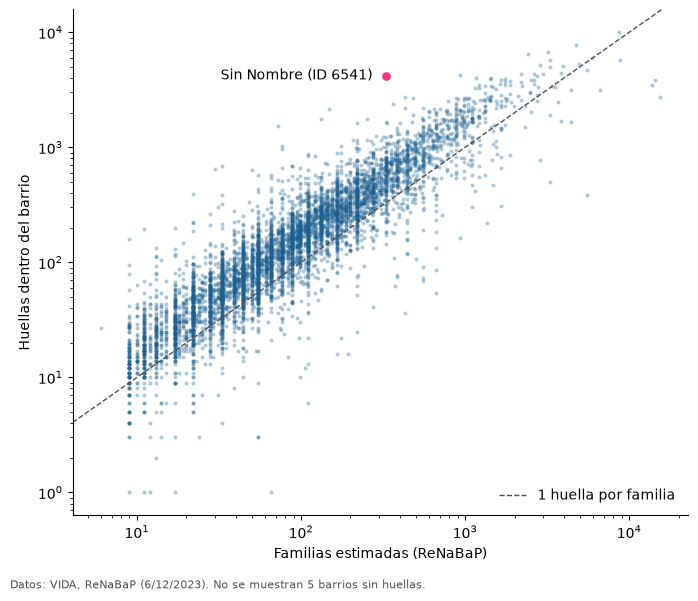

In [14]:
id_caso = 6541  # ex Club Planeadores, ver "Acercarse" más abajo
graficados = barrios[barrios.edificaciones > 0]
caso = barrios[barrios.id_renabap == id_caso]

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(graficados.familias_aproximadas, graficados.edificaciones,
           s=8, color=EDIFICACIONES, alpha=0.35, linewidths=0)
ax.scatter(caso.familias_aproximadas, caso.edificaciones,
           s=60, color=LIMITE, edgecolor="white", linewidth=1.5, zorder=3)
ax.annotate(f"{caso.nombre_barrio.iloc[0]} (ID {id_caso})",
            (caso.familias_aproximadas.iloc[0], caso.edificaciones.iloc[0]),
            xytext=(-10, 0), textcoords="offset points", va="center", ha="right")
ax.axline((10, 10), (100, 100), color="#52514e", linestyle="--", linewidth=1,
          label="1 huella por familia")
ax.legend(loc="lower right", frameon=False)
ax.set(xscale="log", yscale="log",
       xlabel="Familias estimadas (ReNaBaP)",
       ylabel="Huellas dentro del barrio")
ax.spines[["top", "right"]].set_visible(False)
fig.text(0.01, 0.01, FUENTE + f". No se muestran {len(barrios) - len(graficados)} "
         "barrios sin huellas.", fontsize=8, color="#52514e")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig("outputs/huellas_vs_familias.png", dpi=200)
plt.show()

**Figura 2. Huellas por familia estimada.** Cada barrio aparece como un punto en el mapa nacional. Pasá el cursor sobre un punto para ver la estimación de familias y el conteo de huellas.

In [15]:
puntos = barrios.copy()
puntos.geometry = puntos.geometry.representative_point()

mapa_nacional = puntos.explore(
    column="grupo",
    cmap=["#1d6090", "#7fa6c9", "#a3a29c", "#f58db5", "#c8105f"],
    tiles=SATELITE, attr=FUENTE_SATELITE,
    marker_kwds={"radius": 4},
    style_kwds={"fillOpacity": 0.9, "weight": 1, "color": "white"},
    tooltip=["nombre_barrio", "localidad", "provincia",
             "familias_aproximadas", "edificaciones"],
    legend_kwds={"caption": "Huellas por familia estimada"},
)
mapa_nacional.save("outputs/mapa_nacional.html")
mapa_nacional

## Acercarse al ex Club Planeadores

En Los Hornos, La Plata, VIDA muestra **4.202** huellas dentro del polígono donde el ReNaBaP estima **330 familias**. El registro lista varios barrios de Los Hornos como *Sin Nombre*. Usá el ID `6541` para encontrar este. La nota técnica describe cómo creció el barrio.

In [16]:
barrios.loc[
    (barrios.localidad == "Los Hornos")
    & (barrios.nombre_barrio == "Sin Nombre"),
    ["id_renabap", "nombre_barrio", "familias_aproximadas", "edificaciones"],
]

,id_renabap,nombre_barrio,familias_aproximadas,edificaciones
36,43,Sin Nombre,32,53
39,46,Sin Nombre,330,831
42,49,Sin Nombre,143,308
69,79,Sin Nombre,275,892
781,863,Sin Nombre,209,537
934,1034,Sin Nombre,66,109
953,1055,Sin Nombre,133,320
6141,6541,Sin Nombre,330,4202


Para dibujar las huellas, el notebook vuelve a hacer el cruce espacial para este barrio. Esta vez conserva las geometrías de las edificaciones y usa la caja delimitadora del barrio para acotar la búsqueda. La caja encuentra las candidatas, y `ST_Contains` sigue decidiendo qué huellas cuentan. La consulta pasa ese subconjunto a GeoPandas para mapearlo.

In [17]:
limite = barrios[barrios.id_renabap == id_caso]
oeste, sur, este, norte = limite.total_bounds

huellas = gpd.GeoDataFrame.from_arrow(con.sql(f"""
    SELECT e.source, e.confidence, e.geometry
    FROM '{edificaciones_parquet}' AS e
    JOIN '{renabap_parquet}' AS b
      ON ST_Contains(b.geometry, ST_PointOnSurface(e.geometry))
    WHERE b.id_renabap = {id_caso}
      AND e.bbox.xmin < {este} AND e.bbox.xmax > {oeste}
      AND e.bbox.ymin < {norte} AND e.bbox.ymax > {sur}
""").arrow())

In [18]:
print(f"{miles(len(huellas))} huellas, "
      f"{miles(limite.familias_aproximadas.iloc[0])} familias estimadas")
huellas.source.value_counts().rename("huellas por fuente")

4.202 huellas, 330 familias estimadas


source
google       4185
microsoft      17
Name: huellas por fuente, dtype: int64

**Figura 3. Huellas en el ex Club Planeadores.** El mapa muestra las huellas sobre imágenes satelitales (Esri). Usá el control de capas para mostrar u ocultar las huellas. Buscá grupos de techos sin contorno. ¿Están en los bordes o entre viviendas muy juntas? ¿Están en zonas que parecen de construcción reciente? Buscá también varios techos dibujados como una sola huella. Un techo sin contorno puede ser una edificación que no se detectó o una construida después de la fecha de la imagen de origen. Anotá qué ves y dónde. Cada patrón te da algo para revisar en el campo.

In [19]:
mapa_local = huellas.explore(
    color=EDIFICACIONES, tiles=None, name="Huellas de VIDA",
    tooltip=["source", "confidence"],
    style_kwds={"weight": 1, "fillOpacity": 0.35},
)
limite.explore(m=mapa_local, color=LIMITE, name="Polígono del ReNaBaP",
               tooltip=["nombre_barrio", "id_renabap", "familias_aproximadas"],
               style_kwds={"fill": False, "weight": 3})
folium.TileLayer(SATELITE, name="Imagen satelital (Esri)", attr=FUENTE_SATELITE,
                 max_zoom=20, max_native_zoom=19).add_to(mapa_local)
folium.LayerControl().add_to(mapa_local)
mapa_local.save("outputs/mapa_planeadores.html")
mapa_local

## Próximos pasos

Probá el flujo de trabajo en un barrio que conozcas. Cambiá `id_caso` por su ID del ReNaBaP y volvé a ejecutar las celdas desde la Figura 1. Elegí algunas manzanas donde veas un patrón y revisalas con vecinos, vecinas u otras personas que trabajen ahí. Averiguá qué estructuras son viviendas, dónde comparten edificación varias familias y qué edificaciones faltan en el mapa. Llevá un relevamiento reciente o imágenes con fecha si los tenés.

Compartí lo que encuentres y hacé las mismas revisiones en un barrio construido de otra manera. El objetivo es descubrir en conjunto dónde pueden ayudar las huellas en tu zona, por ejemplo para elegir manzanas para volver a relevar o para revisar la exposición a inundaciones. Para ver un ejemplo de cómo el ReNaBaP combinó imágenes, visitas de campo y el conocimiento de los vecinos, consultá **Territorio y detección remota: el ciclo del dato** en la nota técnica.

## Sobre los datos de huellas

Elegimos las huellas de VIDA a partir de nuestra propia experiencia al explorar distintos mapas de huellas de edificaciones y ver cuáles parecen corresponder mejor con lo que se ve en las imágenes. Otras opciones son [Overture Maps](https://docs.overturemaps.org/guides/buildings/) y [OpenStreetMap](https://www.openstreetmap.org). Nos interesaría que se compare la precisión de estas fuentes con validación en campo. Ese trabajo es difícil, y es el siguiente paso lógico.

**Limitaciones.** Estos conteos son huellas, no viviendas ni hogares. No analizamos:

- Cómo se usan las edificaciones, incluido si son residenciales o si están ocupadas. Las edificaciones que no son viviendas suben el conteo.
- Si las edificaciones tienen varios pisos o alojan a varias familias. Esas edificaciones bajan el conteo.
- Las edificaciones que faltan en las huellas y las construcciones más nuevas que las imágenes de las huellas. Las dos bajan el conteo.

Combiná los conteos con otras fuentes, como relevamientos de campo y el conocimiento de los vecinos.